# Causal Inference in the Absence of Randomization

<div>
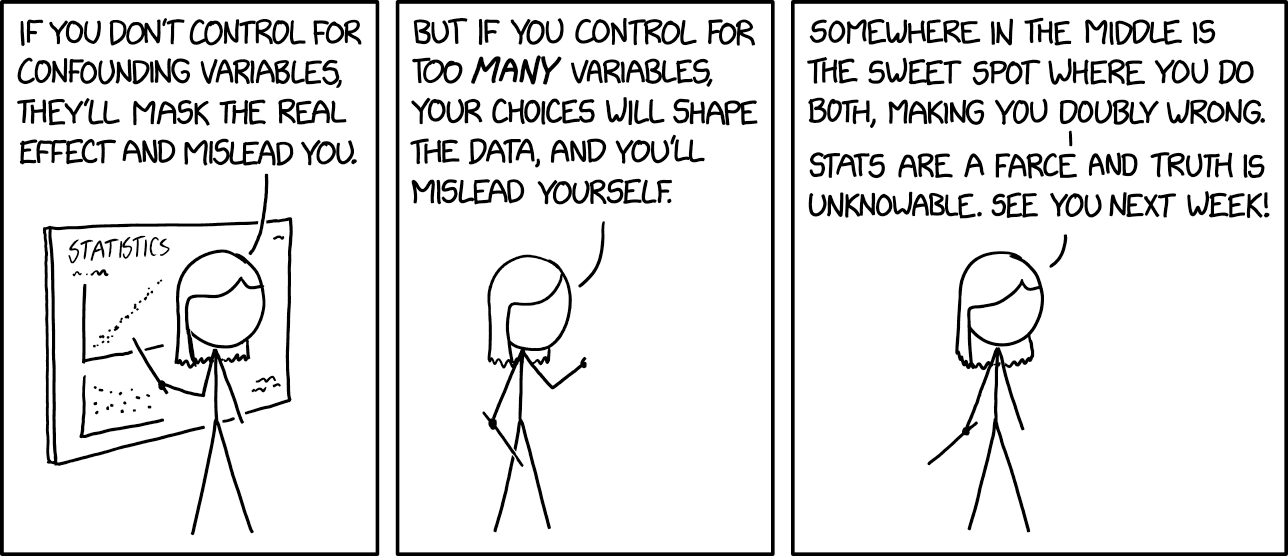
</div>
-XKCD's wisdom regarding confounding variables

<br><br>
This lesson has three goals:
- Introduce the [Conditional Independence Assumption (CIA)](#Conditional-Independence-Assumption)
- Discuss good and bad controls using [Directed Acyclic Graphs (DAGs)](#Directed-Acyclic-Graphs)
- Introduce [Omitted Variable Bias (OVB)](#Omitted-Variable-Bias)
    
In the last lesson, we learned about the potential outcomes framework, and discussed why RCTs (i.e., A/B tests) have a causal interpretation. However, there will be many times when we can't run an experiment, but we still want to undertake causal inference. The good news is that it's possible -- in theory -- to construct a regression so that the coefficient on your independent variable of interest has a causal interpretation.

This lesson formalizes the requirements for a regression to have a causal interpretation, and introduces an intuitive framework to conceptualize these requirements. Moreover, it will introduce you to the different types of biases that arise when a regression is specified incorrectly, so that you can better understand why any given regression might *not* have a causal interpretation. At the end of this lesson, you should be able to better answer the question, "which regression do I want to run?"

<a id='Conditional-Independence-Assumption'></a>
## The Conditional Independence Assumption (CIA)

In the previous lesson we introduced the potential outcomes framework in order to more precisely determine the causal effect of some treatment. In particular, we said that each individual, denoted by i, might be treated ($D_{i} = 1$) or untreated ($D_{i} = 0$). Given this notation, we could think about an individual's outcome in two potential states of the world: one in which they are treated ($Y_{1i}$) and one in which they are untreated ($Y_{0i}$). Finally, we noted that the key reason A/B tests have a causal interpretation is because randomization ensures individuals' potential outcomes are independent of treatment status; that is, the following condition holds:
\begin{equation*}
    \{Y_{0i}, Y_{1i}\} \perp\!\!\!\!\!\perp  D_{i}
\end{equation*}

When working with observational data, we can't rely on randomization to ensure that potential outcomes are independent from treatment status. It could always be the case that selection bias is present, which we now know prevents any causal interpretation of the difference between test and control group outcomes. Still, all hope is not lost. Given the right set of controls, $X_{i}$, we can construct our comparison so that treatment status is independent of potential outcomes, *conditional on our control variables*. Stated formally, we want a rich enough set of controls so that the following assumption seems reasonable:

\begin{equation*}
    \{Y_{0i}, Y_{1i}\} \perp\!\!\!\!\!\perp  D_{i} | X_{i}
\end{equation*}

This mathematical statement is called the Conditional Independence Assumption (CIA), and it allows us to interpret the difference in outcomes across treated and untreated observations with the same level of $X_{i}$ as the causal effect of treatment for those individuals. Returning to math notation, if we believe the CIA, then the following holds:

\begin{equation*}
   \underbrace{E[Y_{1i} | X_{i}, D_{i} = 1] - E[Y_{0i} | X_{i}, D_{i} = 0]}_\text{Observed difference in outcomes for given level of $X_{i}$} \hspace{7mm}= \underbrace{E[Y_{1i} - Y_{0i}| X_{i}]}_\text{Causal effect for given level of $X_{i}$}
\end{equation*}
> **Note**: the equation for the causal effect above is quite similar to the equation for the Average Treatment Effect; however, it is true only for individuals with the given level of $X_{i}$. Recall that when we could randomly assign treatment status (e.g., when using an A/B test), our equation for the ATE was: $\underbrace{E[Y_{1i}\text{ } | \text{ } D_{i} = 1] - E[Y_{0i} \text{ } | \text{ } D_{i} = 0]}_\text{Observed difference in group outcomes} = \underbrace{E[Y_{1i} - Y_{0i}]}_\text{Average treatment effect}$

To drive home the intuition underlying the CIA, we can consider a simple hypothetical example. Let's suppose we want to know the effect of enrolling in NRG's average billing program on customer satisfaction. If you compare the satisfaction ratings of enrollies and non-enrollies, you might be worried that selection bias is present, as individuals who enroll in average billing are likely to have lower satisfaction to begin with. However, if we are able to apply the CIA, we can argue that the seletion bias disappears if we compare customers with the same values of $X_{i}$. For the sake of simplicity, let's suppose that the only source of selection bias stems from there being two types of customers: high usage customers and low usage customers. In this scenario, let's suppose that high usage customers are more likely to enroll in average billing than low usage customers, and that high usage customers tend to also have lower customer satisfaction due to their larger bills. 

Because we have assumed that selection bias only stems from whether a customer has high or low usage, we can eliminate selection bias by controlling for each type of customer. In this case, you could measure the causal effect of the average billing program by comparing the difference in satisfaction levels of enrollies and non-enrollies within the high usage and low usage groups. From these two causal effects, you could find the ATE as the weighted average of the two types in the population and the ATT as the weighted average of the two types among average billing enrollies.
> Note that a regression model assumes linearity. This is a bit more restrictive than the above process of simply comparing subgroups. The "linearity assumption" means that regressions impose the assumption that the estimated causal effect is constant, so in practice we generally won't estimate multiple causal effects within our model.

Again, this example illustrates that *we are assuming treatment status is independent of potential outcomes, conditional on $X_{i}$* (hence the name Conditional Independence Assumption). The assumption part of this statement is critical, so let's be a little bit more clear about exactly what it is we're assuming here. Earlier I said that we are assuming the only source of selection bias stems from differences between high-usage and low-usage customers. This is true, but it isn't stated in a statistically precise way. We can more explicity state our assumption as follows: whatever is causing variation in average billing enrollment is as good as if it came from an experiment, once we condition on usage type. Following this line of reasoning but at a more general level, any time we invoke the CIA we are saying that our identifying variation is as good as if it came from an experiment.
> Recall that "identifying variation" refers to variation in our treatment variable that is unexplained by covariates. In this case "identifying variation" = "variation in customers' average billing enrollment status after controlling for usage type." You can return to our first lesson for an in-depth description of identifying variation and the Frisch-Waugh-Lovell theorem.

Thinking in these terms forces us to come up with a plausible story for why individuals within each group might enroll in average billing. In an experiment we would randomly assign customers of either usage type to the average billing program; in this example, something like being randomly assigned to a really good customer service rep that encouraged the customer to enroll in averge billing would approximate experimental variation. On the other hand, if what's causing variation in customers' enrollment status is really just a variable that we omitted from our analysis, then our CIA is no longer defensible. For example, if customers with lower incomes are more likely to enroll in average billing, after conditioning on customer usage, then our identifying variation is not as good as if it came from an experiment. In this case, our estimated effect of average billing enrollment would be biased.

Lastly, keep in mind that our Condititional Independence Assumption is just that -- an assumption. You can't explicity prove that it's true. However, you should be able to construct a rich enough set of controls that it's not obviously false. The extent to which you are able to convince people that you have estimated a causal effect will often rest on your ability to convince them that your CIA is justified.

<a id='Directed-Acyclic-Graphs'></a>
## Good Controls, Bad Controls, and Directed Acyclic Graphs (DAGs)

We just discussed the need to defend our CIA any time we claim to be estimating a causal effect with observational data. This hinges on our ability to argue that our control variables account for anything that might cause selection bias. But how do we know which control variables to use? Just as importantly, which control variables should we *not* use?

To help answer this question, Directed Acyclic Graphs (DAGs) are an incredibly useful tool. DAGs map out the relationship between our X and Y variables in some specific ways. So, before we start drawing and utilizing DAGs, let's introduce some of the language and disclaimers surrounding them.

At the most basic level, DAGs are constructed out of nodes and arrows. Nodes represent the variables in our study, while arrows between nodes represent a causal effect between two variables. The direction of the arrow indicates the direction of causality, and the pattern of the arrow (solid or dashed) indicates whether the relationship is observed or unobserved in our data. Importantly, the lack of an arrow between nodes implies that there is no causal relationship between them.

Causal effects may be either direct ($X \rightarrow Y$), or mediated by a third variable ($X \rightarrow Z \rightarrow Y$). When the effect of X on Y is mediated by Z, it means that X indirectly causes Y by first causing a change in Z. An example of this might be pulling a hot baking sheet out of the oven and burning your hand. In this case, the oven caused your burn, but indirectly; it first heated the pan, which in turn burned your hand $(\text{oven}\rightarrow \text{hot pan} \rightarrow  \text{burn status})$. In general, these indirect effects may have any number of steps -- the important thing is that they always captures a sequence of events that originates with $X$ and results in $Z$ causally impacting $Y$.

There may also be back door paths between $X$ and $Y$, in which the observed causal pathways do not flow uni-directionally from $X \rightarrow Y$. In these cases, causality can either flow from a third variable, $Z$ ($X \leftarrow Z \rightarrow Y$), or toward the third variable ($X \rightarrow Z \leftarrow Y$). In the former case, we call $Z$ a confounding variable. In the latter case, $Z$ is known as a collider. 

These types of backdoor paths are often the primary challenges we must face when measuring a causal relationship. We'll talk at more length about these relationships in the succeeding section, but the top line takeaway is that we want to make sure all back door paths are closed when we run any regression with a causal interpretation. We will see that in order to close backdoor paths, we sometimes need to include the third variable in our regression and sometimes do not.

To see these ideas in practice, let's start by considering a relatively simple DAG:
<br>

<center><img src="./images/simple_dag.png" width=500 height=500 /></center>
<br>

Let's suppose that we are interested in the causal effect of $X$ on $Y$. In the above DAG, we can see that there exists a direct path from $X$ to $Y$, $X \rightarrow Y$, which indicates a direct causal effect. However, there is also a backdoor path from running through $X$, $X \leftarrow Z \rightarrow Y$. Note that the direction of the arrows indicates that this secondary connection between $X$ and $Y$ is not causal. Instead, $Z$ is a source of spurious correlation between $X$ and $Y$.

One of the great features included in DAGs is that they explicitly force us to think about backdoor paths. In this case, because $Z$ jointly determines $X$ and $Y$, it will confound (i.e., bias) a naive regression of $Y$ on $X$. Thus, we call $Z$ a "confounding" variable in this analysis, and we need to add it as a control in our regression if we want to estimate the causal effect of $X$ on $Y$. If we do so, we can consider the backdoor path "closed." Again, as causal inference practitioners, **we want to close any/all backdoor paths between $X$ and $Y$.**

At this point we understand that we should control for $Z$, but you might still be wondering *why* we need this control. You can grasp the intuition by thinking about how $Y$ reflects changes in $X$. Sometimes, changes in $Y$ are correlated with changes in $X$ independent of $Z$, which is the causal relationship we are interested in. But other times changes in $Y$ and $X$ are correlated because of a third variable, $Z$, which makes this portion of the relationship spurious. If we don't control for $Z$ in our regression then we mix these two types of correlations together, yielding an incorrect estimate for our causal effect.
> Leveraging our discussion in the previous section, we can actually be a bit more precise about this intuition. What's going on here can best be understood through identifying variation and, in turn, the Conditional Independence Assumption. When we estimate the causal effect of $X$ on $Y$, we want to be able to defend the assumption that the identifying variation in $X$ is as good as if it came from an experiment, conditional on the covariates in our regression. If some of the identifying variation in $X$ is actually driven by an omitted variable, $Z$, then our CIA is indefensible and the effect we have estimated is not causal. We therefore need to control for $Z$ in our regression to satisfy the CIA.

This example has illustrated how a confounding variable might impact bias our estimated causal effect. Confounders are good controls, meaning that should include them in our regression if at all possible. However, sometimes that isn't possible. Consider the same example, but when $Z$ is unobserved in the data. In this case, our DAG would look like the following:
<br>

<center><img src="./images/unobserved_dag.png" width=500 height=500 /></center>
<br>

Here, the dashed lines indicate a relationship between variables that is unobserved in our data. This means that we can't add $Z$ to our regression and the backdoor path $X \leftarrow Z \rightarrow Y$ will remain open in spite of our best efforts. Unfortunately this is sometimes just the way it goes in the world of causal inference.


Beyond confounders, there are some variables the we *don't* want to control for. We call these variables colliders, and their presence alone shuts down backdoor paths without adding them to our regression. In the context of a DAG, we can represent a collider as follows:
<br>

<center><img src="./images/collider_dag.png" width=500 height=500 /></center>
<br>

The difference between this DAG and our first is that the direction of causaility along our backdoor path has been reversed; that is, our backdoor path is now $X \rightarrow Z \leftarrow Y$. However, the causal pathways linking $X$ and $Y$ *collide* at $Z$, hence the name collider. The effect of this collision is to cancel out the effect of this backdoor path without the need for us to control for it in our regression. In fact, if we were to control for $Z$ it would actually bias our estimated causal effect.

To understand why this is the case, we can return to our discussion of the CIA and identifying variation. In this case, $Z$ is correlated with both $X$ and $Y$, but only insofar as it is an *outcome* of both variables (note that in this case the relationship is direct, though in principle it could also be a mediated). If we were to control for $Z$, we would be unnecesarily removing identifying variation that is needed to estimate the causal effect of $X$. As a consequence, our estimated effect will be biased.

Finally, let's consider mediating variables. Mediators are just variables that lie along an indirect causal path from $X \rightarrow Y$. Usually mediators are variables that we don't want to control for, but that could change depending on the context of the research question at hand. To represent a mediating variable, consider the following DAG:
<br>

<center><img src="./images/mediator_dag.png" width=500 height=500 /></center>
<br>

In this case, the causal effect of $X$ on $Y$ occurs through two pathways: there is a direct path, $X \rightarrow Y$, and an indirect path $X \rightarrow Z \rightarrow Y$ (note that this is not the same as a backdoor path). If we want to know the total causal effect of $X$ on $Y$, then we should not control for $Z$. On the other hand, if we want to know the effect of $X$ on $Y$ for a given level of $Z$, then we should use it as a control variable. Usually when we attempt to estimate the effect of $X$ on $Y$, we are interested in the former.

Bad controls are often misunderstood in public discourse -- even within the context of high profile legal and/or policy decisions. To drive this point home, let's consider a case presented in [Chapter 3](https://mixtape.scunning.com/03-directed_acyclical_graphs#fnref6) of Scott Cunningham's excellent causal inference textbook, [Causal Inference: The Mixtape](https://mixtape.scunning.com/)

In 2017, Google faced a lawsuit for gender discrimination in employee compensation that received national attention. While the plaintiffs claimed that Google systematically underpaid female employees, Google contended that its data showed that when you take “location, tenure, job role, level and performance” the payment gap disappeared.

Using our newfound causal inference expertise, let's consider whether controlling for occupational differences is useful when estimating the effect of discrimination on income by examining the following DAG:

<br>

<center><img src="./images/bad_controls_example_dag.png" width=500 height=500 /></center>
<br>

Here, $F$ is a variable indicating individuals' gender, $D$ represents discrimination, $O$ represents occupation, $A$ represents (unobserved) ability, and $Y$ represents income. What we are saying in this DAG is that women are assumed to be just as productive as men; there is no direct link between $F$ and $Y$. However, we are positing that being female causes one to experience discrimination, which both directly and indirectly affects income. In particular, discrimination indirectly affects income by causing women to sort into different types of occupations than men. Compounding this relationship, individuals' unobserved ability ($A$) affects both their occupation ($O$) and income ($Y$). 

Given this DAG, we are assuming in this example that these are the only factors that determine income. We would like to set up a regression to determine the causal effect of gender discrimination on earnings. In this DAG we have stated that discrimination is observable, so we can add it as a variable in our regression. But what other controls should we include in our regression?

To determine which controls are good and which controls are bad, notice that there are two indirect paths through which the discrimination-income relationship exists:
 - $D \rightarrow O \rightarrow Y$
 - $D \rightarrow O \leftarrow A \rightarrow Y$

Let's note how controlling for $O$ will impact our estimated effect. Our first indirect path, $D \rightarrow O \rightarrow Y$, shows that $D$ is mediated by $O$. Thus, if we control for $O$ in our regression, we will not be estimating the full effect of discrimination on earnings; instead we will only be estimating the effect of discrimination on earnings for *those with similar occupations*. Within the context of the Google lawsuit, this is a bad idea: the plaintiffs are alleging discrimination, and it would be disingenuous to only partially measure how discrimination is expressed in the workplace.

Our second indirect path, $D \rightarrow O \leftarrow A \rightarrow Y$, is even more clearly problematic. Ability impacts both occupation ($O$) and income ($Y$), but $O$ acts as a collider along this path. This means that conditioning on $O$ would actually *open* this backdoor path, biasing our estimated effect of $D$.

For both these reasons, occupation is a bad control when measuring the effect of gender discrimination on earnings. Even in the most charitable case where we want to evaluate the mediated effect of discrimination on earnings for women in similar occupations, we wouldn't want to control for occupation alone. If we did want to estimate this mediated causal effect, the DAG above makes it clear that we should condition on *both* $O$ and $A$. However, we can't do that because $A$ is unobserved. We therefore lack the ability to construct this estimator.

We can see from this example that bad controls occur for two reasons. First, any control that opens a backdoor path will bias our estimated effect, and should not be included in our regression. Second, we need to be careful to include mediating variables as controls only if they align with our research question. This is a nuanced and subtle issue, and it takes careful thought to determine whether mediators are bad controls. Moreover, this example showed that it is possible for both of these issues to be present within the same variable; here, occupation is both a mediator and a collider along a backdoor path.

<a id='Omitted-Variable-Bias'></a>
## Omitted Variable Bias (OVB)

The last section ended on a bit of a sour note -- after all, is there any way to deal with unobserved variables? We can't control for them, and they'll certainly bias our estimated effect. Moreover, this problem extends to any variable omitted from our data; there are lots of variables out there, and it's quite possible we'll forget to include one or more in our model.

This line of inquiry leads us to think about omitted variable bias (OVB). Omitted variable bias is a catch-all phrase for the bias present in a regression's coefficient of interest when we exclude good controls (either observed or unobserved) from our regression. Obviously, the best way to deal with OVB is to just re-run your regression, but include the omitted variable as a control. There will be many times, however, when you will not be able to do this quickly or the omitted variable is unobserved. In these cases, you should at least be able to think about how the omitted variable will impact your estimated effect. If you're lucky, it may be that including the variable would make your results even stronger, which usually goes over quite well with your audience.

To think clearly about OVB, let's consider the simplest case possible where the true model has two $X$ variables. For concreteness, let's imagine that we would like to determine the causal effect of years of schooling on income. Further, for the sake of this example let's make the heroic assumption that income is entirely determined by two factors: years of schooling and years of work experience. In this simplified case, our model would be:

\begin{equation*}
    \text{income}_{i} = \beta_{0} + \beta_{1}\text{schooling}_{i} + \beta_{2}\text{experience}_{i} + \epsilon_{i}
\end{equation*}
<br>
Making the generous assumption that this regression has a causal interpretation, let's consider what would happen to our estimated coefficient on years of school if we omitted years of experience from our regression and instead ran the following regression:
\begin{equation*}
    \text{income}_{i} = b_{0} + b_{1}\text{schooling}_{i} + \nu_{i}
\end{equation*}
<br>
You should recall from lesson 1 that for a bivariate regression, our estimated coefficient can be described as:

\begin{equation*}
    b_{1} = \frac{\text{Cov(schooling, income)}}{\text{Var(schooling)}}
\end{equation*}
<br>
Because we have assumed that income is actually determined by our regression on schooling _and_ experience, we can plug that regression in for income:

\begin{equation*}
    b_{1} = \frac{\text{Cov(schooling, }\beta_{0} + \beta_{1}\text{schooling}_{i} + \beta_{2}\text{experience}_{i} + \epsilon_{i})}{\text{Var(schooling)}}
\end{equation*}
<br>
Years of schooling is uncorrelated with $\beta_{0}$ and $\epsilon_{i}$, and $Cov(schooling, schooling) = Var(schooling)$. Using these details, we can simplify our expression above to:

\begin{equation*}
    b_{1} = \frac{\beta_{1}\text{Var(schooling) }+ \beta_{2}\text{Cov(schooling, experience)}}{\text{Var(schooling)}}
\end{equation*}
<br>
This further simplifies to:
\begin{equation*}
    b_{1} = \beta_{1} + \beta_{2}(\frac{\text{Cov(schooling, experience)}}{\text{Var(schooling)}})
\end{equation*}

Notice that $b_{1}$ is equal to our true parameter, $\beta_{1}$, _plus_ an additional term. This additional term is our omitted variable bias, so let's spend a little bit of time thinking about it even more deeply. In particular, you should notice that the piece that $\beta_{2}$ has the familiar covariance divided by variance structure. This means that it's equivalent to the coefficient that would arise from a bivariate regression of years of experience on years of schooling. In other words, if you ran the regression

\begin{equation*}
    \text{experience}_{i} = \delta_{0} + \delta_{1}\text{schooling}_{i} + \rho_{i}
\end{equation*}
then
\begin{equation*}
    \delta_{1} = \frac{\text{Cov(schooling, experience)}}{\text{Var(schooling)}}
\end{equation*}

__Thus, our omitted variable bias in this case is $\beta_{2}\delta_{1}$.__

When thinking about how to quantify OVB, first note that OVB is actually not a problem if you can argue that $\beta_{2}$ or $\delta_{1}$ are 0. In this situation, $\beta_{2}\delta_{1} = 0$. The intuition underlying this result is that your omitted variable is either uncorrelated with your outcome of interest, or uncorrelated with with your $X$ variable of interest. 

Sadly, most of the time you will not be able to make this argument. In this case, let's consider how our OVB term will cause $b_{1}$ to differ from $\beta_{1}$. To do this, we will need to figure out whether $\beta_{2}\delta_{1}$ is positive or negative. In turn, this depends on whether $\beta_{2}$ and $\delta_{1}$ are individually positive or negative. This requires understanding how our omitted variable is correlated with our $y$ variable, and how our omitted variable is corrlated with our $X$ variable of interest. The table below summarizes how these correlations determine the sign of your OVB.
<br>

| | <div style="width:150px">$Corr(x_{1}, x_{2}) > 0$</div> | <div style="width:150px">$Corr(x_{1},x_{2}) < 0$</div> | 
| :-------------: | :-------------: | :-------------: |
| <div style="width:150px">$Corr(y, x_{2}) > 0$</div> | <div style="width:150px">$\beta_{2}\delta_{1} > 0$</div> | <div style="width:150px">$\beta_{2}\delta_{1} < 0$</div> |
| <div style="width:150px">$Corr(y, x_{2}) < 0$</div> | <div style="width:150px">$\beta_{2}\delta_{1} < 0$</div> | <div style="width:150px">$\beta_{2}\delta_{1} > 0$</div> |

The takeaway here is that if you can sign your OVB, you can determine whether or not it's a problem for your results. In our running example, our omitted variable is years of work experience. In this case, OVB is plausibly negative. To see why, first note that years of experience is positively correlated with income ($\beta_{2} > 0$). Second, it may be the case that individuals with more years of schooling have less years of work experience, since those who go to school full time often don't have jobs. In this case, years of work experience is negatively correlated with years of schooling ($\delta_{1} < 0$). This puts us in the top right cell of our table above, where $\beta_{2}\delta_{1} < 0$. Thus, our estimated effect of schooling when OVB is present is actually _smaller_ than the true effect. This means that any effect we find is actually a conservative estimate of the true effect of schooling on income. By extension, we can defend our results against critics who would claim there is no relationship between years of schooling and income.

One last note about OVB is in order. The discussion above is true specifically when there are two $X$ variables; if you have more than that, signing OVB gets a bit trickier. Still, the procedure we have outlined here is _usually_ directionally correct, and very few people take issue with applying it to situations with many $X$ variables. Memorizing the table above is extremely useful for presenting your results to technical audiences, so it's worth spending a few minutes to do so.

## Conclusion

In conclusion, DAGs are powerful tools. By clarifying how variables are related, they also make clear what assumptions we are building into our model, and how well equipped we are to undertake causal inference. Moreover, they help us better understand which variables should be included in our model, and which should not. They are a natural extension to the potential outcomes framework we discussed in our last lesson, and, as such, should be a foundational tool when you undertake future causal inference projects.

Moreover, if you notice that your model has omitted confounders contained in your DAG, you can now think more clearly about whether they are a threat to identifying a causal effect. By understanding the basics of OVB, you can better defend your results and make smarter decisions about when to describe your results as causal.